In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/My Drive/2Tresample_data.csv')

In [ ]:
df.columns

Index(['timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs',
       'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers',
       'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses',
       'Severity', 'Failure', 'Hours_till_Failure'],
      dtype='object')

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Load and preprocess the data
# Convert the timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Drop the timestamp column if it's not needed for prediction
df = df.drop(columns=['timestamp','Severity','Hours_till_Failure'])

# Split the data into features and target
X = df.drop(columns=['Failure'])
y = df['Failure']

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape X for LSTM input (samples, timesteps, features)
# Here, we assume timesteps = 10
timesteps = 10
X_seq = []
y_seq = []

for i in range(len(X_scaled) - timesteps):
    X_seq.append(X_scaled[i:i + timesteps])
    y_seq.append(y.values[i + timesteps])  # Use the original binary y values

X_seq, y_seq = np.array(X_seq), np.array(y_seq)

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, test_size=0.2, random_state=42)

In [ ]:
# Build the LSTM model for binary classification
model = keras.Sequential([
    layers.LSTM(64, activation='relu', return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    layers.Dropout(0.2),
    layers.LSTM(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')  # Sigmoid activation for binary classification
])

# Compile the model with binary crossentropy loss for binary classification
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Print model summary
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 10, 64)              │          20,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 10, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 53,569 (209.25 KB)

 Trainable params: 53,569 (209.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Fit the model
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_test, y_test), verbose=1)

Epoch 1/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 36s 21ms/step - accuracy: 0.9845 - loss: 0.0615 - val_accuracy: 0.9965 - val_loss: 0.0082
Epoch 2/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 21ms/step - accuracy: 0.9954 - loss: 0.0121 - val_accuracy: 0.9962 - val_loss: 0.0090
Epoch 3/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 33s 21ms/step - accuracy: 0.9959 - loss: 0.0105 - val_accuracy: 0.9895 - val_loss: 0.0151
Epoch 4/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 40s 20ms/step - accuracy: 0.9967 - loss: 0.0089 - val_accuracy: 0.9964 - val_loss: 0.0099
Epoch 5/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 40s 20ms/step - accuracy: 0.9962 - loss: 0.0090 - val_accuracy: 0.9983 - val_loss: 0.0058
Epoch 6/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 20ms/step - accuracy: 0.9968 - loss: 0.0083 - val_accuracy: 0.9966 - val_loss: 0.0071
Epoch 7/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 33s 21ms/step - accuracy: 0.9972 - loss: 0.0072 - val_accuracy: 0.9970 - val_loss: 0.0065
Epoch 8/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 33s 21ms/step - accuracy: 0.9971 -

In [ ]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f'Test Loss: {test_loss}')
print(f'Test Accuracy: {test_accuracy}')

# Predict the classes on the test set
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype("int32")  # Convert probabilities to class labels

# Import metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Calculate additional metrics
precision = precision_score(y_test, y_pred_classes, average='weighted')  # Use 'micro', 'macro', or 'weighted' for multi-class
recall = recall_score(y_test, y_pred_classes, average='weighted')
f1 = f1_score(y_test, y_pred_classes, average='weighted')

# Print the metrics
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1-Score: {f1:.4f}')

791/791 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9980 - loss: 0.0050
Test Loss: 0.005701829679310322
Test Accuracy: 0.998024046421051
791/791 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
Precision: 0.9982
Recall: 0.9980
F1-Score: 0.9981


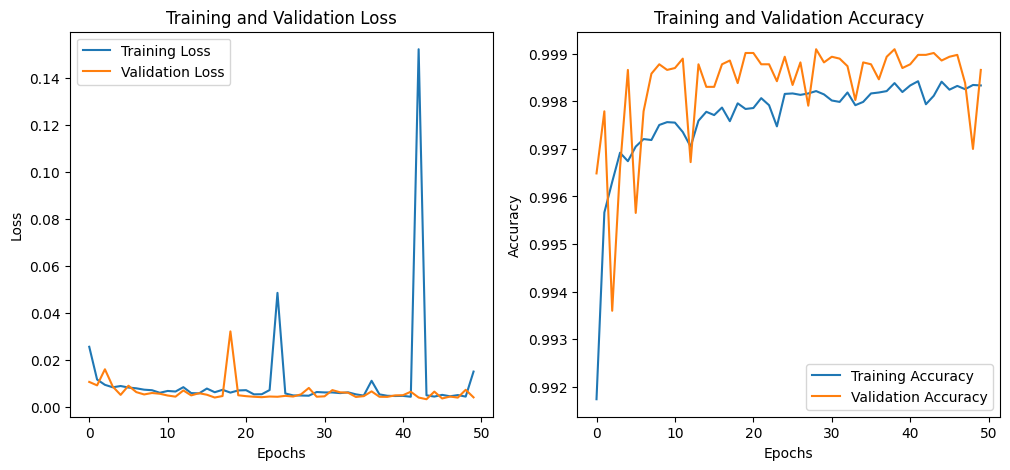

In [ ]:
# Plotting the loss and accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Convert the timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Drop the timestamp column if it's not needed for prediction
df = df.drop(columns=['timestamp'])

# Split the data into features and target
X = df.drop(columns=['Hours_till_Failure'])
y = df['Hours_till_Failure']

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape y to a 2D array for scaling
y_2d = y.values.reshape(-1, 1)  # Reshape to (n_samples, 1)
y_scaled = scaler.fit_transform(y_2d)  # Now you can scale y
y_scaled = y_scaled.ravel()  # Convert back to 1D after scaling if needed


# Reshape X for LSTM input (samples, timesteps, features)
# Here, you can choose the number of timesteps. A common choice is 10.
timesteps = 10
X_seq = []
y_seq = []

for i in range(len(X_scaled) - timesteps):
    X_seq.append(X_scaled[i:i + timesteps])
    y_seq.append(y_scaled[i + timesteps]) # Use the scaled y values

X_seq, y_seq = np.array(X_seq), np.array(y_seq)

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, test_size=0.2, random_state=42)

In [ ]:
# Build the model
model = keras.Sequential([
    layers.LSTM(64, activation='relu', return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])), # return_sequences=True
    layers.Dropout(0.2),  # Dropout layer after the first LSTM
    layers.LSTM(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1)  # Output layer for regression
])

# Compile the model
#model.compile(optimizer='adam', loss='mean_squared_error')
model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error')

# Print model summary
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                        │ (None, 10, 64)              │          20,992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 10, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 54,081 (211.25 KB)

 Trainable params: 54,081 (211.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Fit the model
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_test, y_test), verbose=1)

Epoch 1/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 38s 21ms/step - loss: 0.4496 - val_loss: 0.2526
Epoch 2/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 32s 20ms/step - loss: 0.2568 - val_loss: 0.2068
Epoch 3/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 20ms/step - loss: 0.2183 - val_loss: 0.1866
Epoch 4/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 32s 20ms/step - loss: 0.1968 - val_loss: 0.1651
Epoch 5/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 20ms/step - loss: 0.1851 - val_loss: 0.1544
Epoch 6/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 21ms/step - loss: 0.1733 - val_loss: 0.1501
Epoch 7/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 21ms/step - loss: 0.1689 - val_loss: 0.1396
Epoch 8/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 40s 20ms/step - loss: 0.1606 - val_loss: 0.1403
Epoch 9/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 42s 21ms/step - loss: 0.1522 - val_loss: 0.1370
Epoch 10/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 20ms/step - loss: 0.1501 - val_loss: 0.1350
Epoch 11/50
1582/1582 ━━━━━━━━━━━━━━━━━━━━ 41s 21ms/step - loss: 0.1471 - val_loss: 0.1387
Epoch 12

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
# Evaluate the model on the test data
test_loss = model.evaluate(X_test, y_test)
print(f'Test Loss (Mean Squared Error): {test_loss}')

# Predicting on the test set
y_pred = model.predict(X_test).flatten()  # Flattening to match true labels' shape

# Evaluate with MAE and R² Score
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"R² Score: {r2}")

# If needed, you can inverse the scaling of the predictions
# Note: Inverse scaling is typically done for the y values if they were scaled


791/791 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 0.0922
Test Loss (Mean Squared Error): 0.08898542821407318
791/791 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
Mean Absolute Error (MAE): 0.1971268206342753
R² Score: 0.9117894812287397


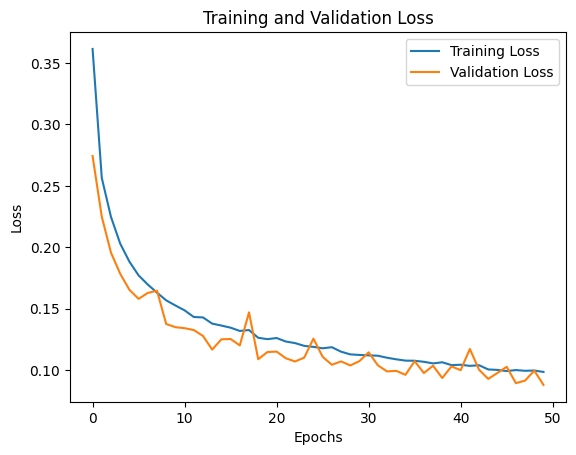

In [ ]:
import matplotlib.pyplot as plt
# Plotting the loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()